Web Data Extraction Completed
Total Books: 1000

Dataset:
                                               Title  Price  Rating  \
0                               A Light in the Attic  51.77       3   
1                                 Tipping the Velvet  53.74       1   
2                                         Soumission  50.10       1   
3                                      Sharp Objects  47.82       4   
4              Sapiens: A Brief History of Humankind  54.23       5   
5                                    The Requiem Red  22.65       1   
6  The Dirty Little Secrets of Getting Your Dream...  33.34       4   
7  The Coming Woman: A Novel Based on the Life of...  17.93       3   
8  The Boys in the Boat: Nine Americans and Their...  22.60       4   
9                                    The Black Maria  52.15       1   

  Availability  
0     In stock  
1     In stock  
2     In stock  
3     In stock  
4     In stock  
5     In stock  
6     In stock  
7     In stock  
8     I

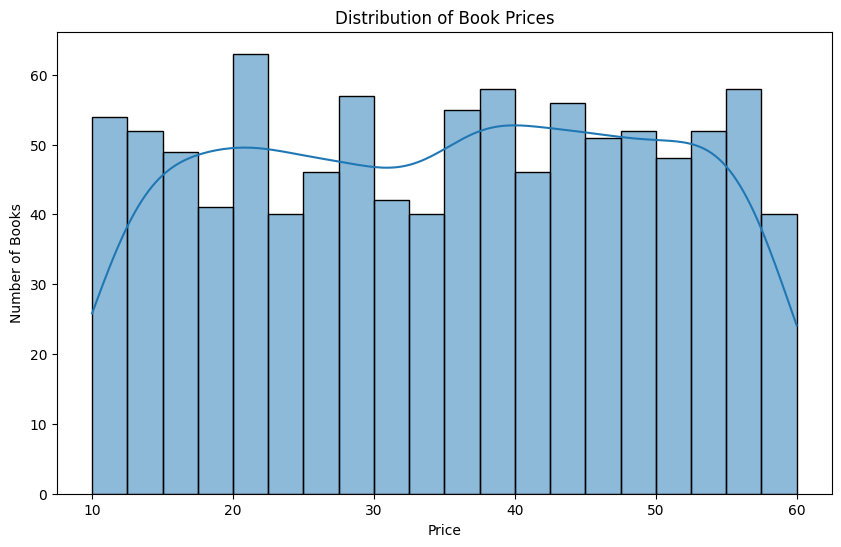

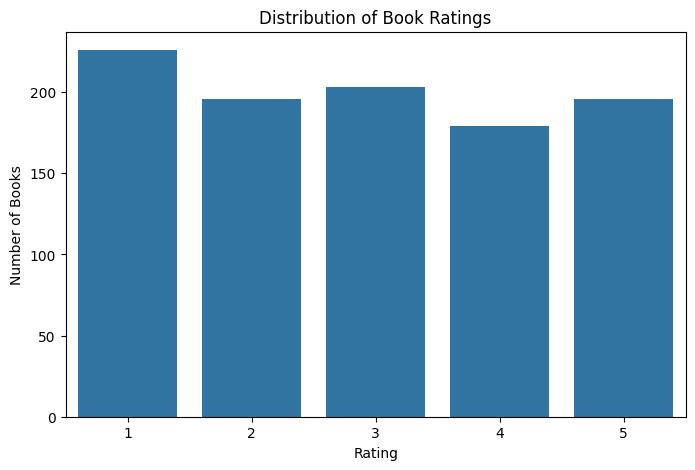

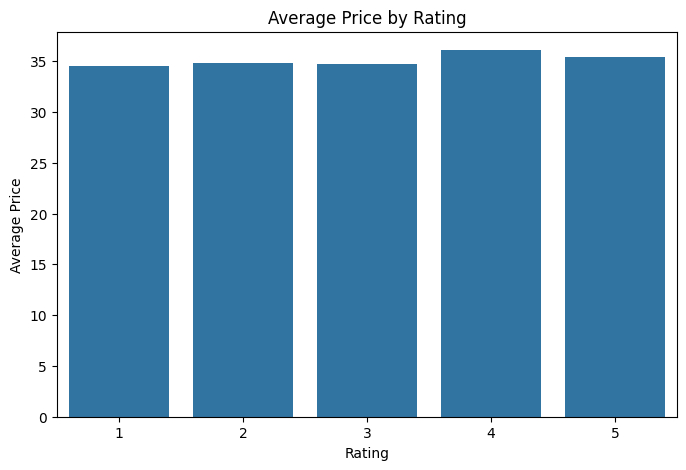

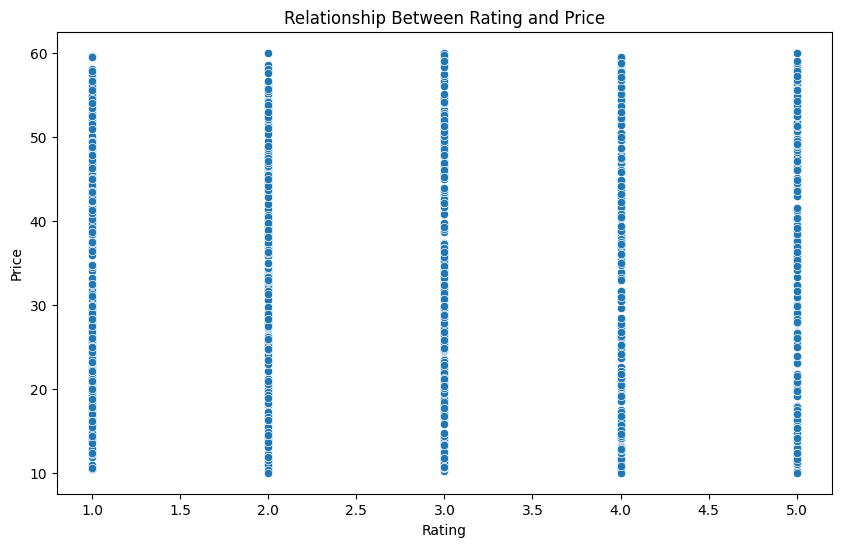

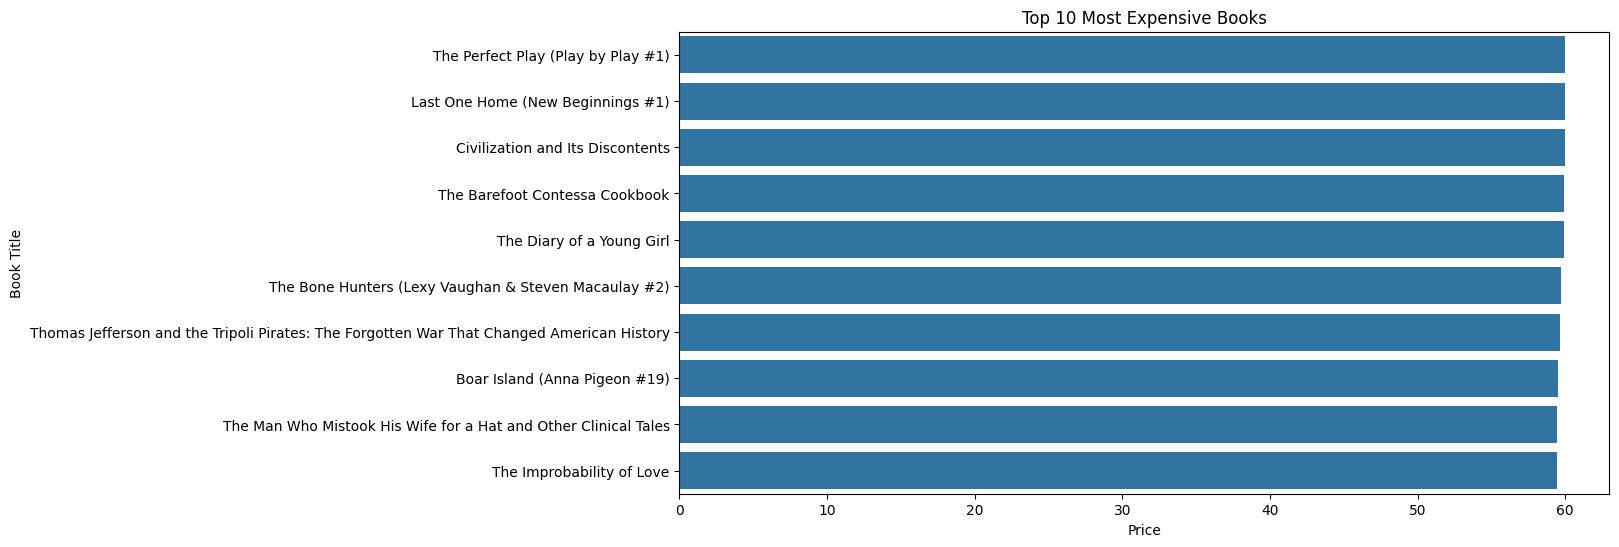


Rating Analysis:
   Rating  Average_Price  Book_Count
0       1      34.561195         226
1       2      34.810918         196
2       3      34.692020         203
3       4      36.093296         179
4       5      35.374490         196

Most Expensive Books:
                                                 Title  Price  Rating
648                 The Perfect Play (Play by Play #1)  59.99       3
617                  Last One Home (New Beginnings #1)  59.98       3
860                   Civilization and Its Discontents  59.95       2
560                     The Barefoot Contessa Cookbook  59.92       5
366                          The Diary of a Young Girl  59.90       3
657  The Bone Hunters (Lexy Vaughan & Steven Macaul...  59.71       3
133  Thomas Jefferson and the Tripoli Pirates: The ...  59.64       1
387                      Boar Island (Anna Pigeon #19)  59.48       3
393                          The Improbability of Love  59.45       1
549  The Man Who Mistook His Wife for

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock
5,The Requiem Red,22.65,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock
9,The Black Maria,52.15,1,In stock



Files Created:
1. web_scraped_books.csv
2. web_scraped_books.xlsx


In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

base_url = "https://books.toscrape.com/catalogue/page-{}.html"

books = []

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for page in range(1, 51):
    url = base_url.format(page)
    response = requests.get(url, timeout=10)

    if response.status_code != 200:
        break

    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.select("article.product_pod"):
        title = book.h3.a.get("title", "").strip()

        price_text = book.select_one(".price_color").text.strip()
        price = float(re.sub(r"[^0-9.]", "", price_text))

        rating_class = book.select_one(".star-rating").get("class")
        rating_word = rating_class[1]
        rating = rating_map.get(rating_word, 0)

        availability = book.select_one(".availability").get_text(" ", strip=True)

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability
        })

    time.sleep(0.2)

df = pd.DataFrame(books)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

df = df.drop_duplicates()
df = df.dropna(subset=["Title", "Price", "Rating"])
df = df.reset_index(drop=True)

df.to_csv("web_scraped_books.csv", index=False)
df.to_excel("web_scraped_books.xlsx", index=False)

print("Web Data Extraction Completed")
print("Total Books:", len(df))
print("\nDataset:")
print(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

print("\nAverage Price:", round(df["Price"].mean(), 2))
print("Minimum Price:", round(df["Price"].min(), 2))
print("Maximum Price:", round(df["Price"].max(), 2))
print("Average Rating:", round(df["Rating"].mean(), 2))

plt.figure(figsize=(10, 6))
sns.histplot(df["Price"], bins=20, kde=True)
plt.title("Distribution of Book Prices")
plt.xlabel("Price")
plt.ylabel("Number of Books")
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Rating")
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.show()

rating_price = df.groupby("Rating")["Price"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=rating_price, x="Rating", y="Price")
plt.title("Average Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Rating", y="Price")
plt.title("Relationship Between Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

top_expensive = df.sort_values("Price", ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_expensive, x="Price", y="Title")
plt.title("Top 10 Most Expensive Books")
plt.xlabel("Price")
plt.ylabel("Book Title")
plt.show()

rating_summary = df.groupby("Rating").agg(
    Average_Price=("Price", "mean"),
    Book_Count=("Title", "count")
).reset_index()

print("\nRating Analysis:")
print(rating_summary)

print("\nMost Expensive Books:")
print(df.nlargest(10, "Price")[["Title", "Price", "Rating"]])

print("\nCheapest Books:")
print(df.nsmallest(10, "Price")[["Title", "Price", "Rating"]])

print("\nMost Common Rating:")
print(df["Rating"].mode()[0])

print("\nHighest Rated Books:")
print(df[df["Rating"] == df["Rating"].max()][["Title", "Price", "Rating"]].head(10))

print("\nFinal Dataset:")
display(df.head(20))

print("\nFiles Created:")
print("1. web_scraped_books.csv")
print("2. web_scraped_books.xlsx")